In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

In [2]:
# Load the dataset
data = pd.read_csv('/content/disease_diagnosis.csv')

In [3]:
# Preprocessing
# Split Blood_Pressure_mmHg into systolic and diastolic
data[['Systolic_BP', 'Diastolic_BP']] = data['Blood_Pressure_mmHg'].str.split('/', expand=True).astype(float)

# Drop unnecessary columns
data = data.drop(['Patient_ID', 'Blood_Pressure_mmHg'], axis=1)

# Encode categorical variables (Symptoms and Gender) for Transformer
symptom_cols = ['Symptom_1', 'Symptom_2', 'Symptom_3', 'Gender']
all_symptoms = np.unique(data[symptom_cols].values.ravel())
symptom_to_idx = {symptom: idx + 1 for idx, symptom in enumerate(all_symptoms)}  # 0 for padding
symptom_to_idx['<PAD>'] = 0


In [4]:
# Convert symptoms to sequences
def symptoms_to_sequence(row):
    return [symptom_to_idx.get(row[col], 0) for col in symptom_cols]

data['Symptom_Sequence'] = data.apply(symptoms_to_sequence, axis=1)
symptom_sequences = np.array(data['Symptom_Sequence'].tolist())

In [5]:
# Encode target variable
le = LabelEncoder()
data['Diagnosis'] = le.fit_transform(data['Diagnosis'])
y = data['Diagnosis'].values

In [6]:
# Numerical features
numerical_cols = ['Age', 'Heart_Rate_bpm', 'Body_Temperature_C', 'Oxygen_Saturation_%', 'Systolic_BP', 'Diastolic_BP']
X_numerical = data[numerical_cols].values

In [7]:
# Split data
X_train_seq, X_test_seq, X_train_num, X_test_num, y_train, y_test = train_test_split(
    symptom_sequences, X_numerical, y, test_size=0.2, random_state=42, stratify=y
)

In [8]:
# Normalize numerical features
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

In [9]:
# Compute class weights for imbalance
class_counts = Counter(y_train)
total_samples = len(y_train)
class_weights = {cls: total_samples / (len(class_counts) * count) for cls, count in class_counts.items()}

In [10]:
# Transformer Model
class TransformerEncoder(tf.keras.layers.Layer):
    def __init__(self, num_heads, d_model, d_ff, vocab_size, max_len, rate=0.1):
        super(TransformerEncoder, self).__init__()
        self.d_model = d_model
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model)
        self.pos_encoding = self.positional_encoding(max_len, d_model)
        self.mha = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model)
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(d_ff, activation='relu'),
            tf.keras.layers.Dense(d_model)
        ])
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)

    def positional_encoding(self, max_len, d_model):
        pos = np.arange(max_len)[:, np.newaxis]
        i = np.arange(d_model)[np.newaxis, :]
        angle_rads = pos / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        pos_encoding = angle_rads[np.newaxis, ...]
        return tf.cast(pos_encoding, dtype=tf.float32)

    def call(self, x, training):
        seq_len = tf.shape(x)[1]
        x = self.embedding(x) * tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x += self.pos_encoding[:, :seq_len, :]
        x = self.dropout1(x, training=training)
        attn_output = self.mha(x, x, x)
        out1 = self.layernorm1(x + attn_output)
        ffn_output = self.ffn(out1)
        out2 = self.layernorm2(out1 + ffn_output)
        return out2


In [11]:
# Build the model
vocab_size = len(symptom_to_idx)
max_len = len(symptom_cols)
d_model = 64
num_heads = 4
d_ff = 128
num_classes = len(le.classes_)


In [12]:
# Inputs
symptom_input = tf.keras.Input(shape=(max_len,), dtype=tf.int32, name='symptom_input')
numerical_input = tf.keras.Input(shape=(len(numerical_cols),), name='numerical_input')

In [15]:
# Transformer for symptoms
transformer = TransformerEncoder(num_heads, d_model, d_ff, vocab_size, max_len)
symptom_encoded = transformer(symptom_input, training=False) # Added training=False
symptom_encoded = tf.keras.layers.GlobalAveragePooling1D()(symptom_encoded)

In [16]:
# Concatenate with numerical features
combined = tf.keras.layers.Concatenate()([symptom_encoded, numerical_input])

In [17]:
# Dense layers
x = tf.keras.layers.Dense(128, activation='relu')(combined)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(64, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
output = tf.keras.layers.Dense(num_classes, activation='softmax')(x)


In [18]:
# Compile model
model = tf.keras.Model(inputs=[symptom_input, numerical_input], outputs=output)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
# Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5)

In [38]:
# Train model
history = model.fit(
    [X_train_seq, X_train_num], y_train,
    validation_data=([X_test_seq, X_test_num], y_test),
    epochs=10,
    batch_size=45,
    class_weight=class_weights,
    callbacks=[early_stopping, lr_scheduler],
    verbose=1
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9433 - loss: 0.0545 - val_accuracy: 0.9282 - val_loss: 0.1519 - learning_rate: 1.9531e-06
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9431 - loss: 0.0493 - val_accuracy: 0.9282 - val_loss: 0.1518 - learning_rate: 1.9531e-06
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9234 - loss: 0.0628 - val_accuracy: 0.9282 - val_loss: 0.1520 - learning_rate: 1.9531e-06
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9400 - loss: 0.0554 - val_accuracy: 0.9282 - val_loss: 0.1522 - learning_rate: 1.9531e-06
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9351 - loss: 0.0560 - val_accuracy: 0.9282 - val_loss: 0.1525 - learning_rate: 1.9531e-06
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9421 - loss: 0.0536 - val_accuracy: 0.9282 - val_loss: 0.1526 - learning_rate: 1.9531e-06
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9388 

In [21]:
# Evaluate model
y_pred = model.predict([X_test_seq, X_test_num]).argmax(axis=1)
accuracy = np.mean(y_pred == y_test)
print(f"\nAccuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step

Accuracy: 0.9366

Classification Report:
                              precision    recall  f1-score   support

Allergies (Seasonal or Food)       1.00      1.00      1.00        30
                     Anxiety       0.95      1.00      0.98        20
                  Bronchitis       0.85      1.00      0.92        67
                        Cold       0.62      0.97      0.75        33
                   Cold sore       1.00      1.00      1.00        20
                       Cough       1.00      1.00      1.00        20
                 Dehydration       1.00      1.00      1.00        20
                  Depression       1.00      1.00      1.00        20
                    Diabetes       1.00      1.00      1.00        21
                   Dizziness       1.00      1.00      1.00        20
                   Dry mouth       1.00      1.00      1.00        20
                     Fatigue       1.00      1.00      1.00        20
       

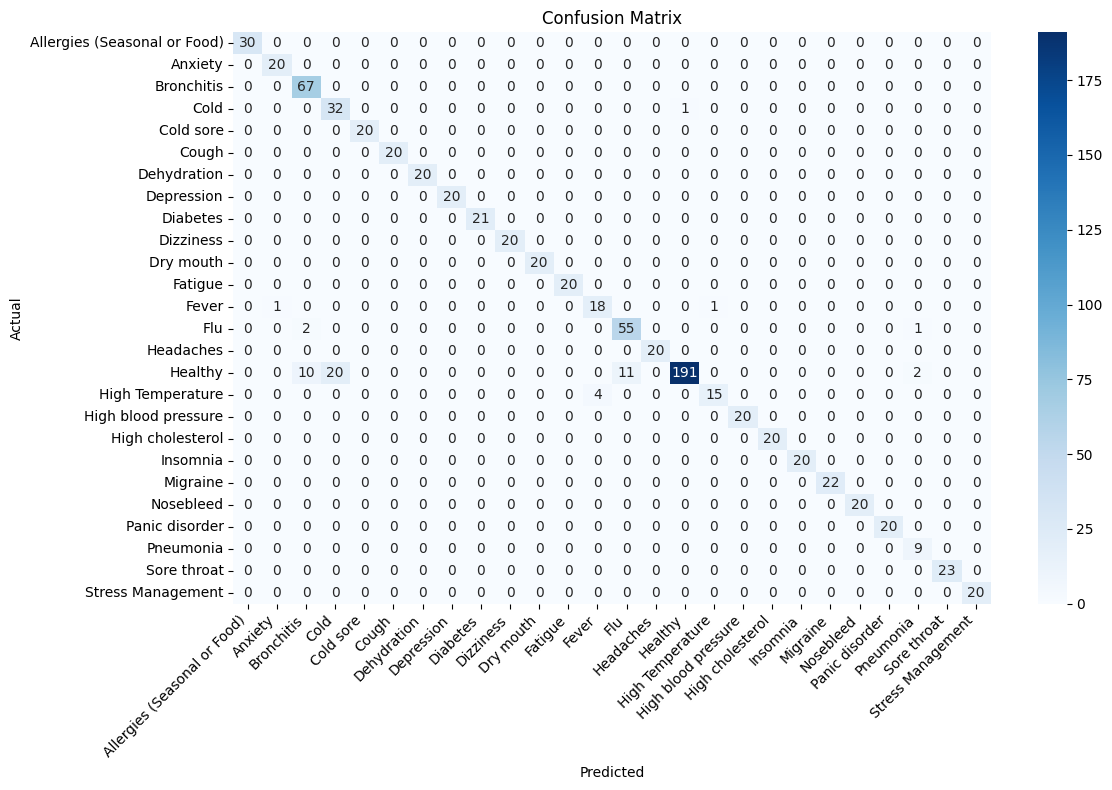

In [24]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

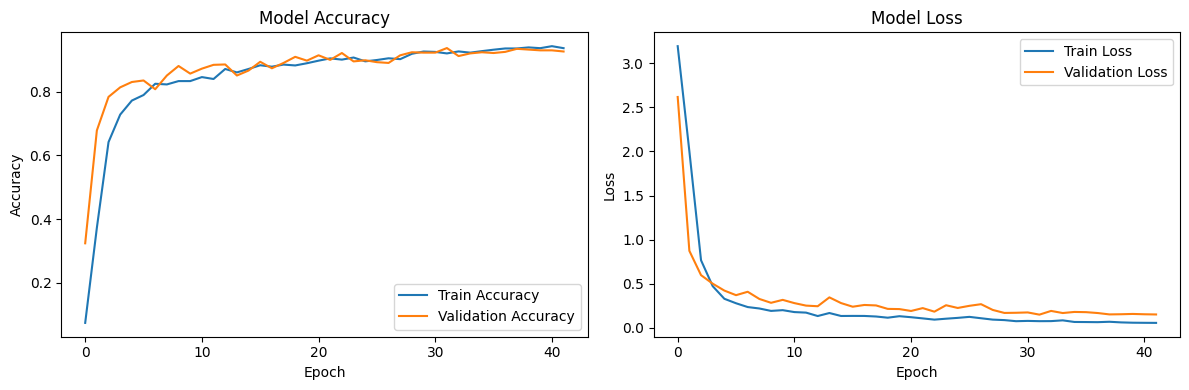

In [25]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [33]:

# Prediction Function with input validation
def predict_disease_transformer(patient_data):
    """
    Predict disease for a new patient with input validation.
    patient_data: dict with keys: Age, Gender, Symptom_1, Symptom_2, Symptom_3,
                  Heart_Rate_bpm, Body_Temperature_C, Blood_Pressure_mmHg, Oxygen_Saturation_%
    """
    required_keys = ['Age', 'Gender', 'Symptom_1', 'Symptom_2', 'Symptom_3',
                     'Heart_Rate_bpm', 'Body_Temperature_C', 'Blood_Pressure_mmHg', 'Oxygen_Saturation_%']

    # 1. Check for missing keys
    if not all(key in patient_data for key in required_keys):
        missing_keys = set(required_keys) - set(patient_data.keys())
        raise ValueError(f"Missing required keys in input: {missing_keys}")

    # 2. Check data types and ranges for numerical features
    numerical_checks = {
        'Age': (lambda x: isinstance(x, (int, float)) and 0 <= x <= 120),
        'Heart_Rate_bpm': (lambda x: isinstance(x, (int, float)) and 40 <= x <= 180),
        'Body_Temperature_C': (lambda x: isinstance(x, (int, float)) and 35 <= x <= 42),
        'Oxygen_Saturation_%': (lambda x: isinstance(x, (int, float)) and 70 <= x <= 100),
        'Systolic_BP': (lambda x: isinstance(x, (int, float)) and 60 <= x <= 200),  # Example ranges
        'Diastolic_BP': (lambda x: isinstance(x, (int, float)) and 40 <= x <= 120)   # Example ranges
    }

    # 3. Check Blood Pressure format
    try:
      patient_data['Systolic_BP'], patient_data['Diastolic_BP'] = map(int, patient_data['Blood_Pressure_mmHg'].split('/'))
    except (ValueError, AttributeError):
        raise ValueError("Invalid Blood_Pressure_mmHg format.  Use 'sys/dia' format (e.g. '120/80').")

    # Create DataFrame and apply preprocessing
    patient_df = pd.DataFrame([patient_data])
    patient_df = patient_df.drop('Blood_Pressure_mmHg', axis=1)

    for col, check_func in numerical_checks.items():
        if not check_func(patient_data.get(col)):
           raise ValueError(f"Invalid value for {col}: {patient_data.get(col)}")

    # 4. Check symptoms against known vocabulary
    for i in range(1, 4):
        symptom = patient_data[f'Symptom_{i}']
        if symptom not in symptom_to_idx:
            raise ValueError(f"Unknown symptom: {symptom}")

    # Symptom sequence
    symptom_seq = np.array([symptoms_to_sequence(patient_df.iloc[0])])

    # Numerical features
    numerical_data = patient_df[numerical_cols].values
    numerical_data = scaler.transform(numerical_data)

    # Predict
    pred = model.predict([symptom_seq, numerical_data]).argmax(axis=1)
    return le.inverse_transform(pred)[0]


In [34]:

new_patient = {
    'Age': 10,
    'Gender': 'Male',
    'Symptom_1': 'Fever',
    'Symptom_2': 'Cough',
    'Symptom_3': 'Headache',
    'Heart_Rate_bpm': 90,
    'Body_Temperature_C': 38.5,
    'Blood_Pressure_mmHg': '130/80',
    'Oxygen_Saturation_%': 95
}
predicted_disease = predict_disease_transformer(new_patient)
print(f"\nPredicted Disease for New Patient: {predicted_disease}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step

Predicted Disease for New Patient: Flu
